# Breast Cancer Classification

## Problem
Build a machine learning model to classify breast tumors as malignant or benign.

## Goal
Compare multiple classification models and select the best model using cross-validation and hyperparameter tuning.

In [4]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)

df = data.frame

X = df.drop(columns='target')
y = df['target']

In [5]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [6]:
df.shape

(569, 31)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [8]:
df.isna().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

In [9]:
y.value_counts()

target
1    357
0    212
Name: count, dtype: int64

In [10]:
y.value_counts(normalize=True)

target
1    0.627417
0    0.372583
Name: proportion, dtype: float64

In [11]:
print(data.target_names)

['malignant' 'benign']


In [12]:
for i, name in enumerate(data.target_names):
    print(i, name)

0 malignant
1 benign


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [18]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

In [16]:
logistic_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=1000))
    ]
)

In [20]:
rf_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('model', RandomForestClassifier(
            n_estimators=100,
            max_depth=5
        ))
    ]
)

In [21]:
from sklearn.model_selection import cross_validate

In [22]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

In [23]:
logistic_cv = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring=scoring
)

In [24]:
rf_cv = cross_validate(
    rf_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring=scoring
)

In [32]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": ['Logistic Regression', 'Random Forest Classifier'],

    "Fit Time": [
        logistic_cv["fit_time"].mean(),
        rf_cv["fit_time"].mean()
    ],

    "Score Time": [
        logistic_cv["score_time"].mean(),
        rf_cv["score_time"].mean()
    ],

    "Accuracy": [
        logistic_cv["test_accuracy"].mean(),
        rf_cv["test_accuracy"].mean()
    ],

    "Precision": [
        logistic_cv["test_precision"].mean(),
        rf_cv["test_precision"].mean()
    ],

    "Recall": [
        logistic_cv["test_recall"].mean(),
        rf_cv["test_recall"].mean()
    ],

    "F1": [
        logistic_cv["test_f1"].mean(),
        rf_cv["test_f1"].mean()
    ],
})

In [33]:
comparison

,Model,Fit Time,Score Time,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.008129,0.005533,0.980220,0.979655,0.989474,0.984344
1,Random Forest Classifier,0.070376,0.006790,0.956044,0.965509,0.964912,0.964997


Logistic Regression performed better than Random Forest Classifier in all four scores. Since identifying malignant cases is particularly important in this problem, recall is an important metric for model selection.

In [34]:
param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

In [35]:
from sklearn.model_selection import GridSearchCV

In [37]:
grid_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='recall'
)

In [38]:
grid_search.fit(X_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, 

In [51]:
grid_search.best_params_

{'model__C': 0.01}

In [52]:
grid_search.best_score_

np.float64(1.0)

In [39]:
best_model = grid_search.best_estimator_

In [41]:
test_pred = best_model.predict(X_test)

In [42]:
y_test_malignant = (y_test==0).astype(int)

In [43]:
test_pred_malignant = (test_pred==0).astype(int)

The original dataset uses 0 for malignant and 1 for benign. I converted malignant to 1 so that malignant represents the positive class during evaluation.

In [44]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score)

In [46]:
accuracy = accuracy_score(y_test_malignant, test_pred_malignant)
precision = precision_score(y_test_malignant, test_pred_malignant)
recall = recall_score(y_test_malignant, test_pred_malignant)
f1 = f1_score(y_test_malignant, test_pred_malignant)

In [47]:
print("Accuracy: ", accuracy)
print("Precision: ", precision)
print("Recall: ", recall)
print("F1: ", f1)

Accuracy:  0.9473684210526315
Precision:  0.9736842105263158
Recall:  0.8809523809523809
F1:  0.925


In [48]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test_malignant,
    test_pred_malignant
)

In [49]:
cm

array([[71,  1],
       [ 5, 37]])

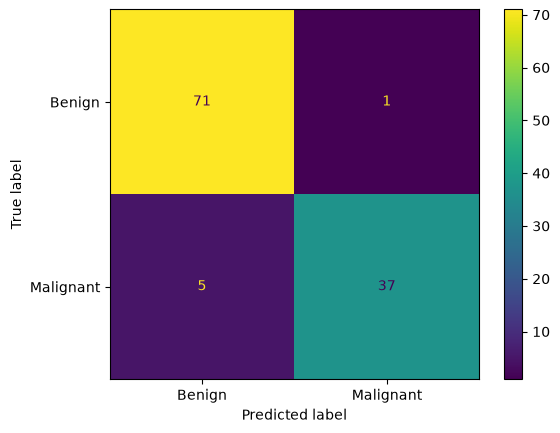

In [50]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test_malignant,
    test_pred_malignant,
    display_labels=["Benign", "Malignant"]
)

In [54]:
cv_recall = grid_search.best_score_

print("Best CV Recall:", cv_recall)
print("Final Test Recall:", recall)
print("Difference:", abs(cv_recall - recall))

Best CV Recall: 1.0
Final Test Recall: 0.8809523809523809
Difference: 0.11904761904761907


A large gap may indicate that the model does not generalize as consistently as expected.

## Conclusion

- Best model: Logistic Regression
- Best hyperparameters: C = 0.01
- Final accuracy: 0.95
- Final precision: 0.97
- Final recall: 0.88
- Final f1: 0.93
- Most important metrics: recall
- Why: Recall is especially important because missing a malignant case can be more costly than incorrectly flagging a benign case as malignant.

An end-to-end machine learning workflow includes data preparation, model comparison, cross-validation, hyperparameter tuning, and final evaluation on unseen test data.